In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!pip -q install gdown ultralytics
!mkdir -p /kaggle/working/yolo_weights
!gdown --folder https://drive.google.com/drive/folders/1-nScFpGMzET1SlvQPrFH1XQwG4ChVA8L -O /kaggle/working/yolo_weights
!find /kaggle/working/yolo_weights -type f -exec ls -lh {} \;

Retrieving folder contents
Processing file 1EBaPnp5OHAmSNgOideWFf0QiBefsNse9 Ball_Detection_Model.pt
Processing file 18dw6se7R3cOuifSd3dhRp80bxTMyyg1A Bat_Detection_Model.pt
Processing file 1HuHV0inj-AwlItJbJgMzEi6zKVSs3q9N Efficientnetv2-s_GRU_128_NEEDS_CROPPED_SEGMENTED_SHOTS.keras
Processing file 1XzWkOrIs9lpuE14XWv_H9gZxP6-VyGW8 Player_Type_Detection_Model.pt
Processing file 1MFi1TuiNaY3DiCi1yWLcwX7O9HQ9nsBH Striker_Bat_Segmentation_Model.pt
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1EBaPnp5OHAmSNgOideWFf0QiBefsNse9
From (redirected): https://drive.google.com/uc?id=1EBaPnp5OHAmSNgOideWFf0QiBefsNse9&confirm=t&uuid=658963be-bec2-4867-a177-ba2e16cbc572
To: /kaggle/working/yolo_weights/Ball_Detection_Model.pt
100%|██████████████████████████████████████| 51.6M/51.6M [00:01<00:00, 46.7MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=18dw6se7R3c

In [5]:
DEBUG = False          # test on 100 clips first, then set False for the full run
NUM_FRAMES = 16
IMG_SIZE = 224
PAD = 0.10            # 10% padding around striker + bat
CONF = 0.25           # YOLO confidence threshold
YOLO_IMGSZ = 640
BATCH_CLIPS = 8

In [6]:
import os, glob
!pip -q install gdown ultralytics
W = '/kaggle/working/yolo_weights'
if not os.path.exists(f'{W}/Player_Type_Detection_Model.pt'):
    !gdown -q --folder https://drive.google.com/drive/folders/1-nScFpGMzET1SlvQPrFH1XQwG4ChVA8L -O {W}
for f in glob.glob(f'{W}/*.keras') + glob.glob(f'{W}/Ball_*'):
    os.remove(f)                      # not needed, saves output space

from ultralytics import YOLO
striker_model = YOLO(f'{W}/Player_Type_Detection_Model.pt')
bat_model     = YOLO(f'{W}/Bat_Detection_Model.pt')
print('Player classes:', striker_model.names)
print('Bat classes:   ', bat_model.names)
STRIKER_ID = [k for k, v in striker_model.names.items() if v.lower() == 'striker'][0]
BAT_ID     = [k for k, v in bat_model.names.items() if 'bat' in v.lower()][0]
print('Striker id:', STRIKER_ID, '| Bat id:', BAT_ID)

Player classes: {0: 'Striker', 1: 'Bat'}
Bat classes:    {0: 'Cricket Bat'}
Striker id: 0 | Bat id: 0


In [7]:
import os, glob
!pip -q install gdown ultralytics
W = '/kaggle/working/yolo_weights'
if not os.path.exists(f'{W}/Player_Type_Detection_Model.pt'):
    !gdown -q --folder https://drive.google.com/drive/folders/1-nScFpGMzET1SlvQPrFH1XQwG4ChVA8L -O {W}
for f in glob.glob(f'{W}/*.keras') + glob.glob(f'{W}/Ball_*'):
    os.remove(f)                      # not needed, saves output space

from ultralytics import YOLO
striker_model = YOLO(f'{W}/Player_Type_Detection_Model.pt')
bat_model     = YOLO(f'{W}/Bat_Detection_Model.pt')
print('Player classes:', striker_model.names)
print('Bat classes:   ', bat_model.names)
STRIKER_ID = [k for k, v in striker_model.names.items() if v.lower() == 'striker'][0]
BAT_ID     = [k for k, v in bat_model.names.items() if 'bat' in v.lower()][0]
print('Striker id:', STRIKER_ID, '| Bat id:', BAT_ID)

Player classes: {0: 'Striker', 1: 'Bat'}
Bat classes:    {0: 'Cricket Bat'}
Striker id: 0 | Bat id: 0


In [9]:
import shutil, subprocess, numpy as np, pandas as pd

# 1. Find the .rar archives (works with the 01 notebook output or the cricshot10k-raw dataset)
rar_files = sorted(glob.glob('/kaggle/input/**/*.rar', recursive=True))
assert rar_files, 'No .rar files found - Add Input: 01-download-cricshot10k (or cricshot10k-raw dataset)'
print('Archives found:', len(rar_files), '| folder:', os.path.dirname(rar_files[0]))

# 2. Make sure an extractor is installed
if shutil.which('unrar') is None and shutil.which('7z') is None:
    subprocess.run('apt-get -qq update && apt-get -qq install -y unrar p7zip-full', shell=True)
print('unrar:', shutil.which('unrar'), '| 7z:', shutil.which('7z'))

# 3. Extract all archives into /tmp/videos
ROOT = '/tmp/videos'
os.makedirs(ROOT, exist_ok=True)
for r in rar_files:
    cmd = (['unrar', 'x', '-o+', '-idq', r, ROOT + '/'] if shutil.which('unrar')
           else ['7z', 'x', '-y', '-bso0', '-bsp0', r, f'-o{ROOT}'])
    res = subprocess.run(cmd, capture_output=True, text=True)
    print(f'{os.path.basename(r):25s} {"OK" if res.returncode == 0 else "FAILED: " + res.stderr[-200:]}')

# 4. Load metadata (same clips, labels and splits as Notebook 02)
meta_files = glob.glob('/kaggle/input/**/metadata.csv', recursive=True)
assert meta_files, 'metadata.csv not found - Add Input: 02-split-and-features'
meta = pd.read_csv(meta_files[0])
missing = [p for p in meta.path if not os.path.exists(os.path.join(ROOT, p))]
print('\nClips in metadata:', len(meta), '| missing video files:', len(missing))
if missing:
    print('Examples of missing:', missing[:5])

work = meta.sample(100, random_state=0).reset_index(drop=True) if DEBUG else meta
print('Clips to process:', len(work))

Archives found: 15 | folder: /kaggle/input/notebooks/srimanreddybommi/01-download-cricshot10k/cricshot10k_raw
unrar: /usr/bin/unrar | 7z: /usr/bin/7z
Cover Drive.rar           OK
Defensive.rar             OK
Down The Wicket.rar       OK
Flick.rar                 OK
Hook.rar                  OK
Late Cut.rar              OK
Lofted Legside.rar        OK
Lofted Offside.rar        OK
Pull.rar                  OK
Reverse Sweep.rar         OK
Scoop.rar                 OK
Square Cut.rar            OK
Straight Drive.rar        OK
Sweep.rar                 OK
Upper Cut.rar             OK

Clips in metadata: 10091 | missing video files: 0
Clips to process: 100


In [13]:
import cv2, torch, logging
from torch.utils.data import Dataset, DataLoader
cv2.setNumThreads(0)
logging.getLogger('ultralytics').setLevel(logging.ERROR)   # hides the 'half' warnings

class FullFrames(Dataset):
    """Returns the 16 uniformly sampled full-resolution frames (BGR) of a clip."""
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        cap = cv2.VideoCapture(os.path.join(ROOT, self.paths[i])); frames = []
        while True:
            ok, f = cap.read()
            if not ok: break
            frames.append(f)
        cap.release()
        idx = np.linspace(0, len(frames) - 1, NUM_FRAMES).round().astype(int)
        return [frames[j] for j in idx], i

def collate_list(batch): return batch

def union(a, b):
    return np.array([min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3])])

def square_box(box, W, H, pad=PAD, min_side=96):
    """Expand a box into a padded square inside the frame (keeps body proportions)."""
    x1, y1, x2, y2 = box
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    side = int(min(max(max(x2 - x1, y2 - y1) * (1 + 2 * pad), min_side), W, H))
    x1 = int(np.clip(round(cx - side / 2), 0, W - side))
    y1 = int(np.clip(round(cy - side / 2), 0, H - side))
    return np.array([x1, y1, x1 + side, y1 + side])

def crop_resize(frame_bgr, box):
    x1, y1, x2, y2 = box.astype(int)
    return cv2.cvtColor(cv2.resize(frame_bgr[y1:y2, x1:x2], (IMG_SIZE, IMG_SIZE),
                                   interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

@torch.no_grad()
def detect(frames):
    """ALL striker candidates per frame as (k, 5) arrays [x1,y1,x2,y2,conf], and the best bat box (or None)."""
    s_cands = [np.zeros((0, 5))] * len(frames)
    b_boxes = [None] * len(frames)
    for s in range(0, len(frames), 64):
        chunk = frames[s:s + 64]
        rs = striker_model.predict(chunk, imgsz=YOLO_IMGSZ, conf=CONF, classes=[STRIKER_ID], half=True, verbose=False)
        rb = bat_model.predict(chunk, imgsz=YOLO_IMGSZ, conf=CONF, classes=[BAT_ID], max_det=1, half=True, verbose=False)
        for k, (a, b) in enumerate(zip(rs, rb)):
            if len(a.boxes):
                s_cands[s + k] = np.concatenate([a.boxes.xyxy.cpu().numpy(),
                                                 a.boxes.conf.cpu().numpy()[:, None]], 1)
            if len(b.boxes):
                b_boxes[s + k] = b.boxes.xyxy[0].cpu().numpy()
    return s_cands, b_boxes

def bat_inside(bat, box, grow=0.3):
    """True if the bat's centre lies inside the (slightly enlarged) person box."""
    bx, by = (bat[0] + bat[2]) / 2, (bat[1] + bat[3]) / 2
    w, h = box[2] - box[0], box[3] - box[1]
    return (box[0] - grow * w <= bx <= box[2] + grow * w) and (box[1] - grow * h <= by <= box[3] + grow * h)

def choose_striker(s_cands, b_boxes, W):
    T = len(s_cands); chosen = [None] * T
    # 1. Trusted frames: a striker candidate is holding the detected bat
    for t in range(T):
        if b_boxes[t] is None or len(s_cands[t]) == 0:
            continue
        holding = [c for c in s_cands[t] if bat_inside(b_boxes[t], c)]
        if holding:
            chosen[t] = max(holding, key=lambda c: c[4])[:4]
    # 2. Drop trusted boxes far from the rest (e.g. bat found on the non-striker)
    idx = [t for t in range(T) if chosen[t] is not None]
    if len(idx) >= 3:
        cx = np.array([(chosen[t][0] + chosen[t][2]) / 2 for t in idx])
        med = np.median(cx)
        for t, c in zip(idx, cx):
            if abs(c - med) > 0.25 * W:
                chosen[t] = None
    # 3. No trusted frame at all: fall back to the most confident striker per frame (paper's rule)
    if all(c is None for c in chosen):
        chosen = [c[c[:, 4].argmax(), :4] if len(c) else None for c in s_cands]
    return chosen

def clip_crops(frames, s_cands, b_boxes):
    """Returns per-frame crops, per-clip crops, final per-frame boxes, clip box, trusted-frame flags."""
    H, W = frames[0].shape[:2]
    chosen = choose_striker(s_cands, b_boxes, W)
    raw = []
    for t, c in enumerate(chosen):
        if c is None:
            raw.append(None)
        elif b_boxes[t] is not None and bat_inside(b_boxes[t], c):
            raw.append(union(c, b_boxes[t]))          # include the bat only if it belongs to this striker
        else:
            raw.append(c)
    found = np.array([r is not None for r in raw])
    if found.any():
        rs = np.stack([r for r in raw if r is not None])
        clip_box = square_box(np.array([rs[:, 0].min(), rs[:, 1].min(), rs[:, 2].max(), rs[:, 3].max()]), W, H)
    else:
        clip_box = np.array([0, 0, W, H])
    frame_boxes = [square_box(r, W, H) if r is not None else clip_box for r in raw]
    per_frame = np.stack([crop_resize(f, b) for f, b in zip(frames, frame_boxes)])
    per_clip  = np.stack([crop_resize(f, clip_box) for f in frames])
    return per_frame, per_clip, np.stack(frame_boxes), clip_box, found

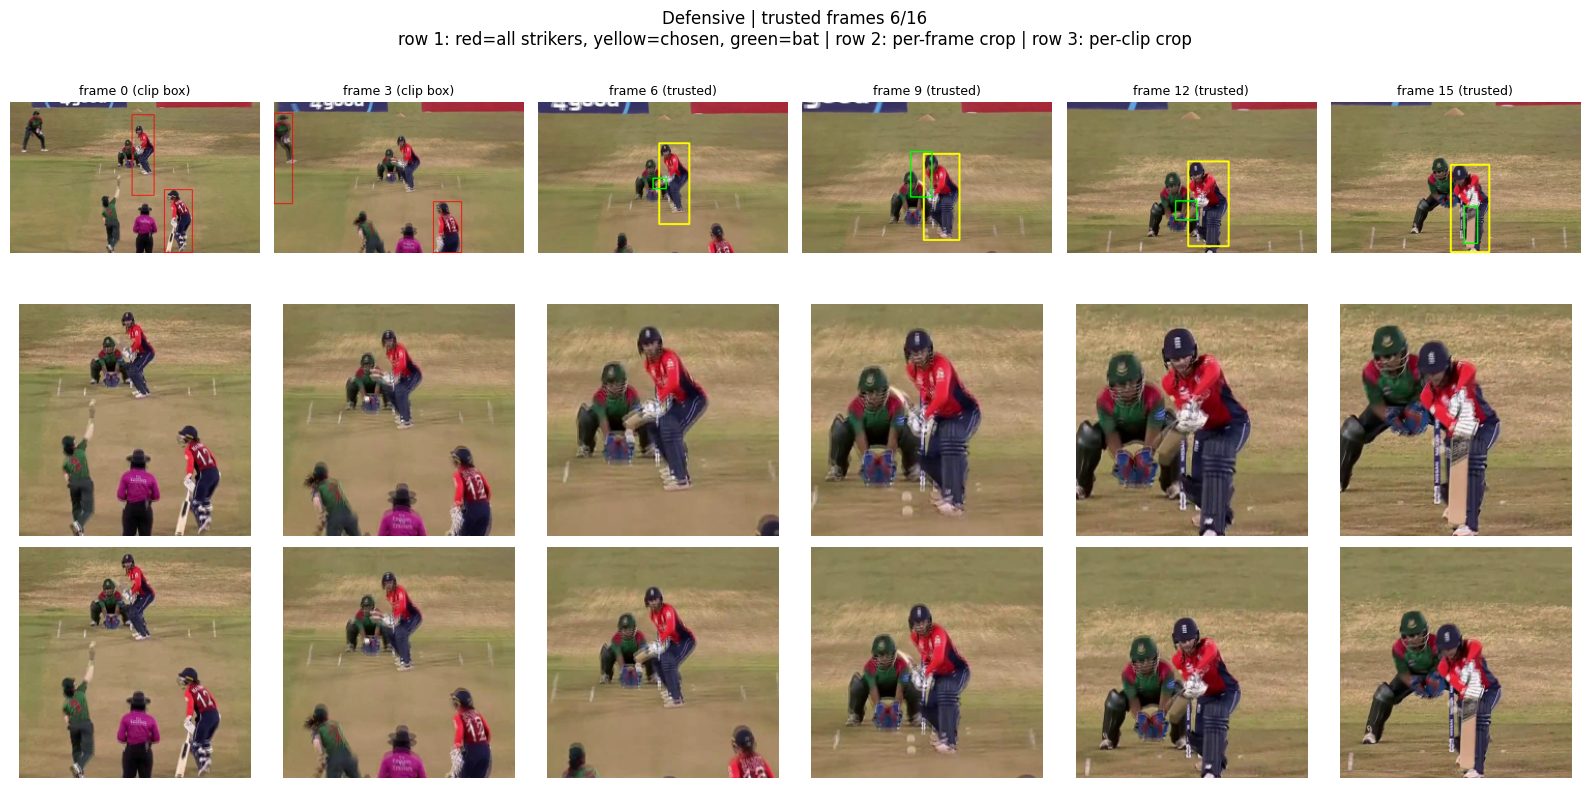

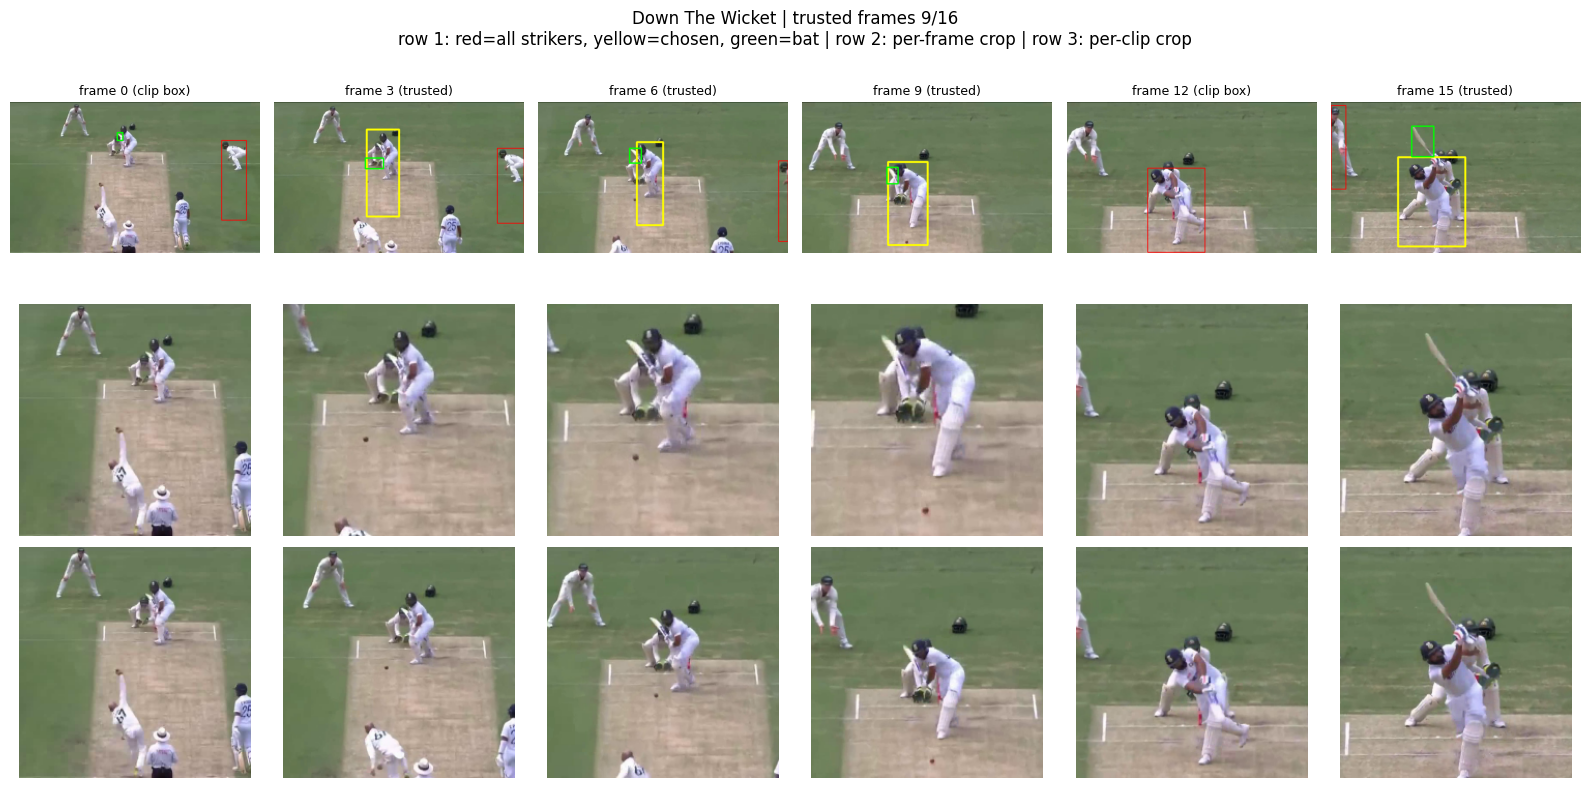

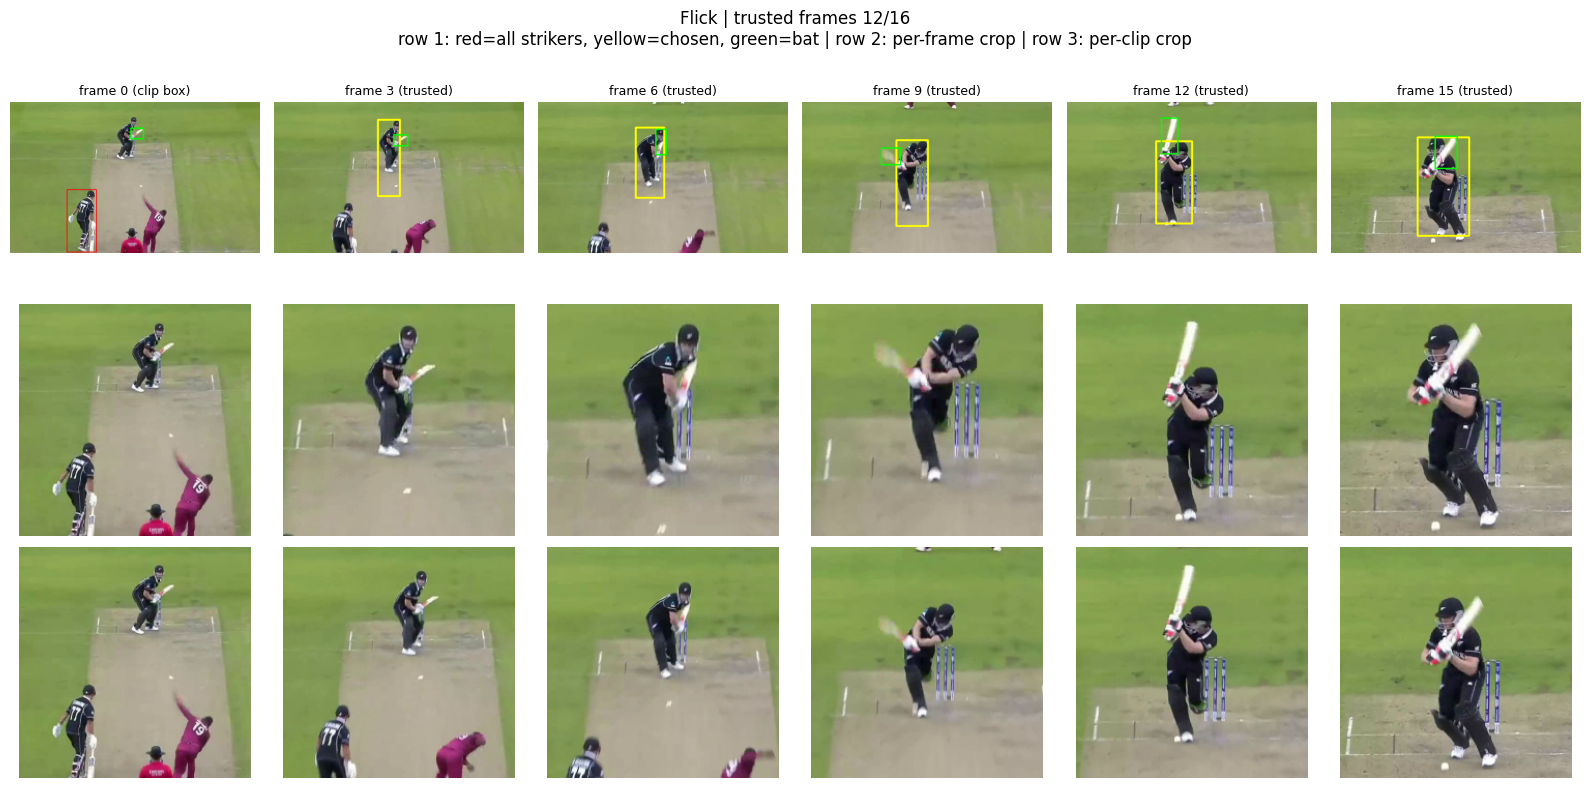

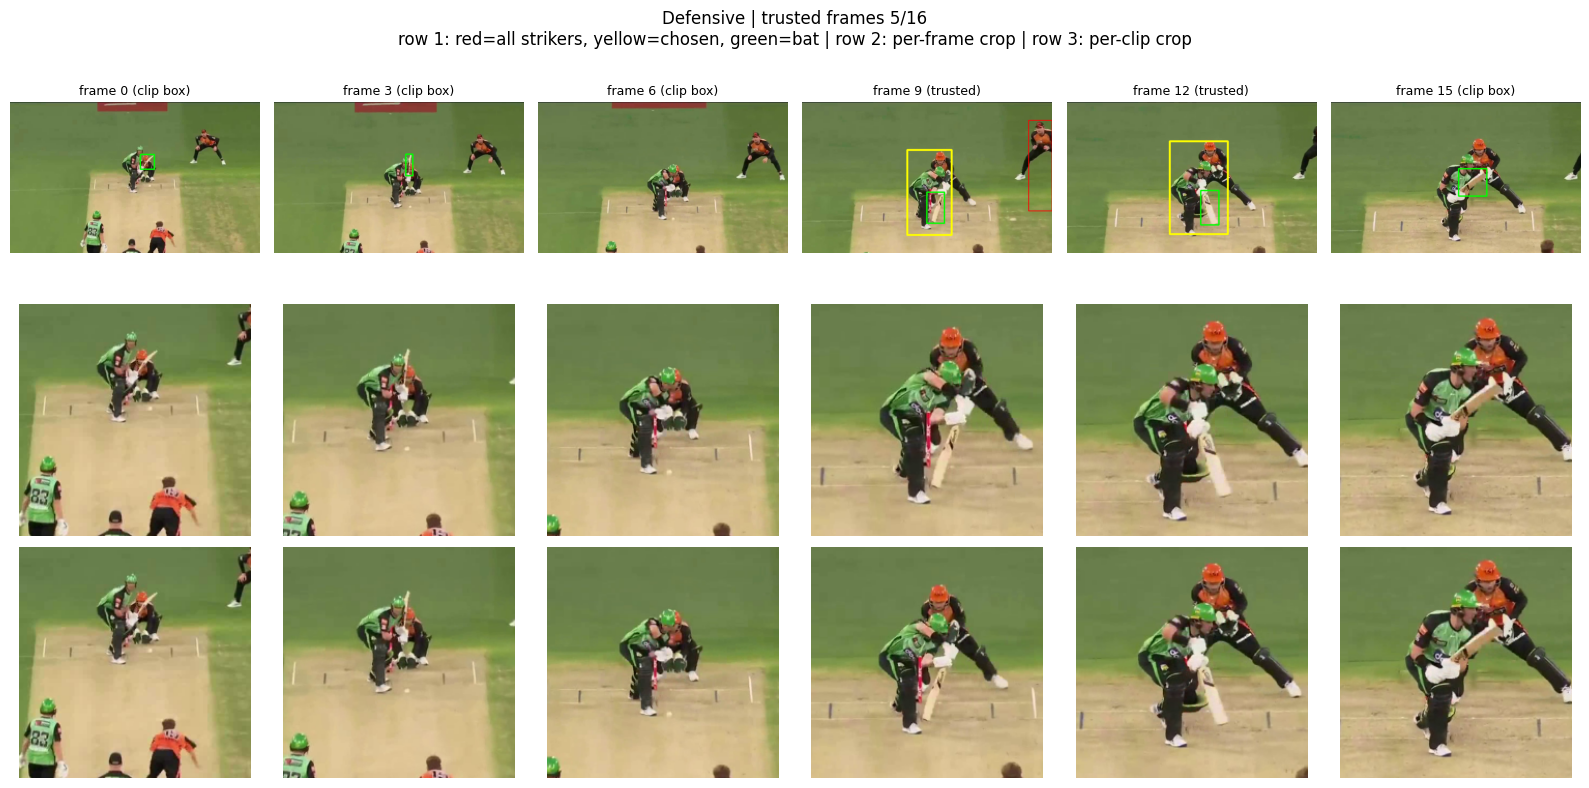

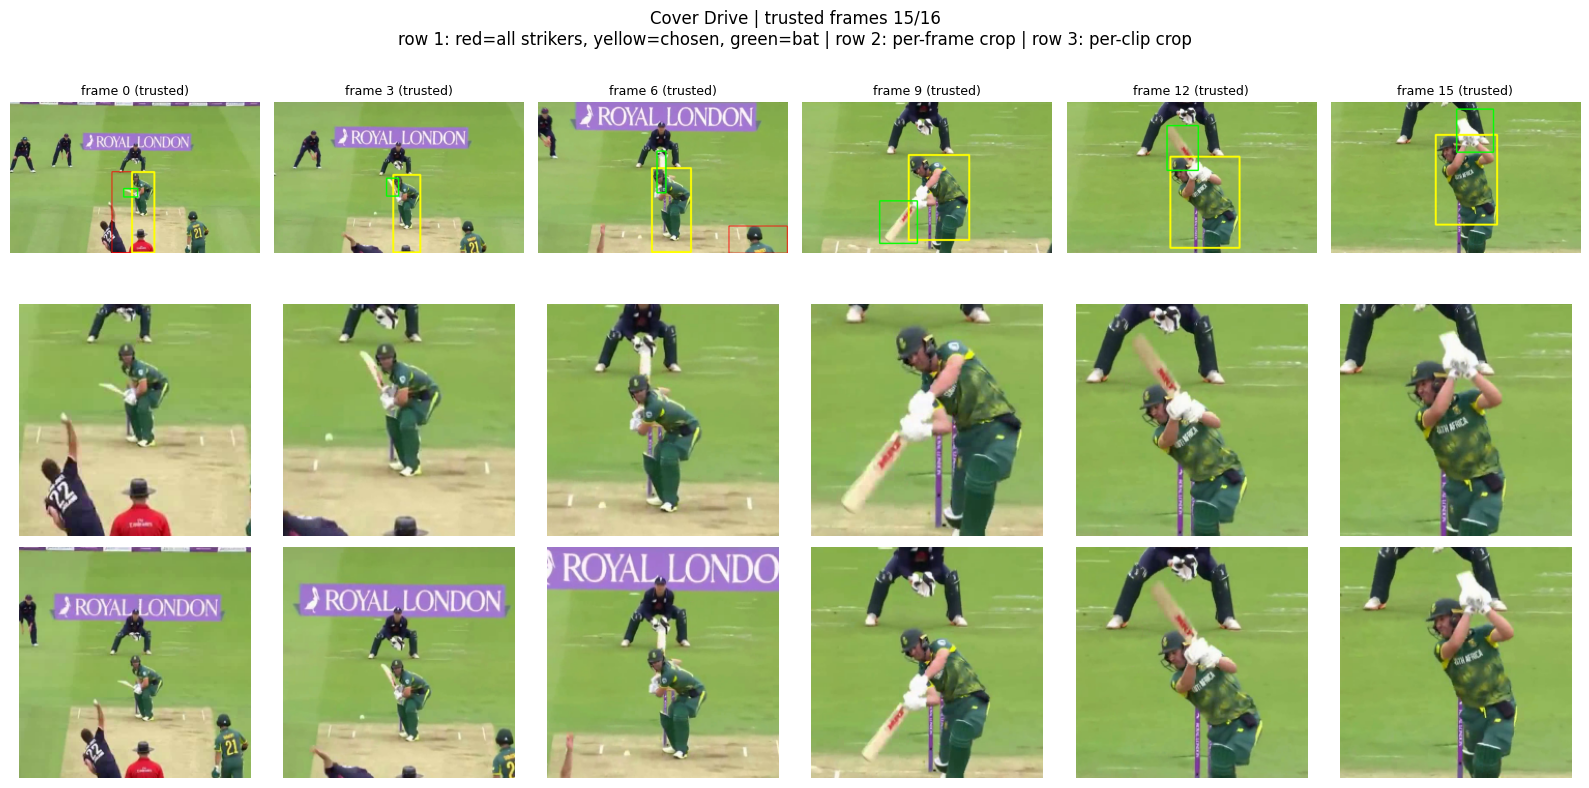

In [14]:
import matplotlib.pyplot as plt
ds = FullFrames(work.path.tolist())
for i in [0, 1, 2, 3, 4]:
    frames, _ = ds[i]
    sc, bb = detect(frames)
    chosen = choose_striker(sc, bb, frames[0].shape[1])
    pf, pc, fboxes, cbox, found = clip_crops(frames, sc, bb)
    fig, ax = plt.subplots(3, 6, figsize=(16, 8))
    for j, t in enumerate([0, 3, 6, 9, 12, 15]):
        img = cv2.cvtColor(frames[t], cv2.COLOR_BGR2RGB).copy()
        for c in sc[t]:                                   # all striker candidates: thin red
            cv2.rectangle(img, tuple(c[:2].astype(int)), tuple(c[2:4].astype(int)), (255, 0, 0), 2)
        if chosen[t] is not None:                         # chosen striker: thick yellow
            cv2.rectangle(img, tuple(chosen[t][:2].astype(int)), tuple(chosen[t][2:4].astype(int)), (255, 255, 0), 5)
        if bb[t] is not None:                             # bat: green
            cv2.rectangle(img, tuple(bb[t][:2].astype(int)), tuple(bb[t][2:].astype(int)), (0, 255, 0), 3)
        ax[0, j].imshow(img); ax[1, j].imshow(pf[t]); ax[2, j].imshow(pc[t])
        ax[0, j].set_title(f'frame {t} {"(trusted)" if found[t] else "(clip box)"}', fontsize=9)
        for r in range(3): ax[r, j].axis('off')
    fig.suptitle(f"{work['class'][i]} | trusted frames {found.sum()}/16\n"
                 "row 1: red=all strikers, yellow=chosen, green=bat | row 2: per-frame crop | row 3: per-clip crop")
    plt.tight_layout(); plt.show()

In [15]:
import torch.nn as nn, torchvision
from torchvision.models import EfficientNet_B0_Weights
device = 'cuda'
m = torchvision.models.efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
backbone = nn.Sequential(m.features, m.avgpool, nn.Flatten()).to(device).eval()
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.no_grad()
def embed(x):                                   # (B, T, H, W, 3) uint8
    B, T = x.shape[:2]
    x = x.permute(0, 1, 4, 2, 3).reshape(B * T, 3, IMG_SIZE, IMG_SIZE).float() / 255.
    with torch.autocast('cuda', dtype=torch.float16):
        f = backbone((x - MEAN) / STD)
    return f.view(B, T, -1).float().cpu().numpy()

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 132MB/s] 


In [16]:
from tqdm.auto import tqdm
import time

N = len(work)
F = {k: np.zeros((N, NUM_FRAMES, 1280), dtype=np.float16)
     for k in ['frame', 'frame_flip', 'clip', 'clip_flip']}
boxes  = np.zeros((N, NUM_FRAMES, 4), dtype=np.int16)
found  = np.zeros((N, NUM_FRAMES), dtype=bool)

loader = DataLoader(FullFrames(work.path.tolist()), batch_size=BATCH_CLIPS,
                    num_workers=4, collate_fn=collate_list)
t0 = time.time()
for batch in tqdm(loader):
    all_frames = [f for frames, _ in batch for f in frames]
    sb, bb = detect(all_frames)
    pfs, pcs, ids = [], [], []
    for c, (frames, i) in enumerate(batch):
        sl = slice(c * NUM_FRAMES, (c + 1) * NUM_FRAMES)
        pf, pc, fb, _, fd = clip_crops(frames, sb[sl], bb[sl])
        pfs.append(pf); pcs.append(pc); ids.append(i)
        boxes[i], found[i] = fb, fd
    pf = torch.from_numpy(np.stack(pfs)).to(device)
    pc = torch.from_numpy(np.stack(pcs)).to(device)
    F['frame'][ids], F['frame_flip'][ids] = embed(pf), embed(torch.flip(pf, dims=[3]))
    F['clip'][ids],  F['clip_flip'][ids]  = embed(pc), embed(torch.flip(pc, dims=[3]))

mins = (time.time() - t0) / 60
print(f'{N} clips in {mins:.1f} min  ->  full dataset estimate: {mins / N * 10091:.0f} min')
print(f'Striker found in {found.mean() * 100:.1f}% of frames; '
      f'clips with no striker at all: {(found.sum(1) == 0).sum()}')

  0%|          | 0/13 [00:00<?, ?it/s]

100 clips in 1.5 min  ->  full dataset estimate: 155 min
Striker found in 54.8% of frames; clips with no striker at all: 0


In [17]:
import json
OUT = '/kaggle/working'
work['striker_frames'] = found.sum(1)
work.to_csv(f'{OUT}/metadata.csv', index=False)
for k, v in F.items():
    np.save(f'{OUT}/feats_b0_crop_{k}.npy', v)
np.save(f'{OUT}/crop_boxes.npy', boxes); np.save(f'{OUT}/striker_found.npy', found)
json.dump({'num_frames': NUM_FRAMES, 'img_size': IMG_SIZE, 'pad': PAD, 'conf': CONF,
           'backbone': 'efficientnet_b0_imagenet1k_v1', 'crop': 'square, striker+bat union'},
          open(f'{OUT}/config.json', 'w'), indent=2)
!ls -lh /kaggle/working

total 16M
-rw-r--r-- 1 root root  157 Oct 27 03:40 config.json
-rw-r--r-- 1 root root  13K Oct 27 03:40 crop_boxes.npy
-rw-r--r-- 1 root root 4.0M Oct 27 03:40 feats_b0_crop_clip_flip.npy
-rw-r--r-- 1 root root 4.0M Oct 27 03:40 feats_b0_crop_clip.npy
-rw-r--r-- 1 root root 4.0M Oct 27 03:40 feats_b0_crop_frame_flip.npy
-rw-r--r-- 1 root root 4.0M Oct 27 03:40 feats_b0_crop_frame.npy
-rw-r--r-- 1 root root 6.1K Oct 27 03:40 metadata.csv
-rw-r--r-- 1 root root 1.7K Oct 27 03:40 striker_found.npy
drwxr-xr-x 2 root root 4.0K Oct 27 03:25 yolo_weights
